# Issue #14: Model Development

**Inputs:** `modelling_dataset.csv`, `backtest_windows.json`, `baseline_metrics.csv` (Issue #13)  
**Outputs (repository root):** `model_cv_results.csv`, `model_comparison.csv`, `model_predictions.csv`, `champion.json`, `models/`, `model_summary_i14.md`

**Procedure**
1. For each backtest window, the training data are all usable days before the window. Predictors that are constant in that training data are excluded (set in Issue #13).
2. Each candidate model is tuned with `TimeSeriesSplit` (5 folds) **inside the training data only**, scored by WAPE.
3. The **champion** is the model family with the lowest mean CV WAPE across the main windows W1–W3. Test sets are not used for selection.
4. Every model is then refitted on the full training data of each window and scored once on its test window, next to the baselines.

In [1]:
from pathlib import Path
def find_root(marker):
    """Repository root = the folder holding `marker` (this folder or its parent)."""
    for p in [Path.cwd(), Path.cwd().parent]:
        if (p / marker).exists():
            return p
    raise FileNotFoundError(f"{marker} not found in this folder or its parent")
import sys
ROOT = find_root("acn_clean_sessions.csv")
sys.path.insert(0, str(ROOT))

import json, warnings
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, ParameterGrid
from sklearn.linear_model import Ridge, Lasso, ElasticNet, PoissonRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", message=".*converge.*")

data = pd.read_csv(ROOT / "modelling_dataset.csv", parse_dates=["date"])
data["holiday_name"] = data["holiday_name"].fillna("")
config = json.loads((ROOT / "backtest_windows.json").read_text())
TARGET, WINDOWS = config["target"], config["windows"]
baseline_metrics = pd.read_csv(ROOT / "baseline_metrics.csv")
MODEL_DIR = ROOT / "models"; MODEL_DIR.mkdir(exist_ok=True)
SEED = 42
print(f"{len(data)} usable days; windows: {list(WINDOWS)}")

1104 usable days; windows: ['W1', 'W2', 'W3', 'S1', 'S2']


## 1. Candidate models

| Model | Type | Why it is a candidate |
|---|---|---|
| Ridge / Lasso / ElasticNet | Linear, scaled inputs | Interpretable; regime flags act as level shifts |
| Poisson regression | Log-linear GLM | Count target; regime effects become **percentage** changes, which fits a ~60% drop better than a fixed number of sessions |
| Random forest | Tree ensemble | Non-linear weekday × regime interactions |
| Gradient boosting / HistGB | Boosted trees | Strong on tabular data; can over-fit small windows, so CV decides |

Tree models cannot extrapolate below the lowest level seen in training; linear and Poisson models can. This matters in the stress windows (Issue #15).

In [2]:
def scaled(m): return make_pipeline(StandardScaler(), m)
CANDIDATES = {
    "Ridge": (scaled(Ridge()), {"ridge__alpha": [0.1, 1, 10, 100]}),
    "Lasso": (scaled(Lasso(max_iter=20000)), {"lasso__alpha": [0.01, 0.1, 0.5, 1]}),
    "ElasticNet": (scaled(ElasticNet(max_iter=20000)), {"elasticnet__alpha": [0.05, 0.2, 1], "elasticnet__l1_ratio": [0.2, 0.5, 0.8]}),
    "Poisson": (scaled(PoissonRegressor(max_iter=3000)), {"poissonregressor__alpha": [0.001, 0.01, 0.1, 1]}),
    "RandomForest": (RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1),
                     {"max_depth": [4, 8, None], "min_samples_leaf": [3, 10]}),
    "GradientBoosting": (GradientBoostingRegressor(random_state=SEED),
                         {"n_estimators": [150, 300], "max_depth": [2, 3], "learning_rate": [0.05], "subsample": [0.8]}),
    "HistGB": (HistGradientBoostingRegressor(random_state=SEED),
               {"max_iter": [150, 300], "max_depth": [3, None], "learning_rate": [0.05], "min_samples_leaf": [10, 20]}),
}

def wape(y, p): return np.abs(np.asarray(p) - np.asarray(y)).sum() / np.asarray(y).sum()
def metrics(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float); e = p - y
    return {"MAE": np.abs(e).mean(), "RMSE": np.sqrt((e ** 2).mean()), "WAPE": np.abs(e).sum() / y.sum(), "bias": e.mean()}
def split(w):
    cfg = WINDOWS[w]
    train = data[data["date"] < cfg["start"]]
    test = data[(data["date"] >= cfg["start"]) & (data["date"] <= cfg["end"])]
    return train, test, cfg["predictors"]

def tune(est, grid, X, y, n_splits=5):
    tscv = TimeSeriesSplit(n_splits=n_splits)
    best = None
    for params in ParameterGrid(grid):
        scores = []
        for tr, va in tscv.split(X):
            m = clone(est).set_params(**params).fit(X.iloc[tr], y.iloc[tr])
            scores.append(wape(y.iloc[va], np.clip(m.predict(X.iloc[va]), 0, None)))
        s = float(np.mean(scores))
        if best is None or s < best[0]: best = (s, params, float(np.std(scores)))
    return best

## 2. Time-series cross-validation inside each window's training data

In [3]:
MAIN = [w for w, c in WINDOWS.items() if c["kind"] == "main"]
cv_rows, best_params = [], {}
for w in WINDOWS:
    train, _, preds = split(w)
    X, y = train[preds], train[TARGET]
    for name, (est, grid) in CANDIDATES.items():
        score, params, sd = tune(est, grid, X, y)
        best_params[(w, name)] = params
        cv_rows.append({"window": w, "kind": WINDOWS[w]["kind"], "model": name, "cv_WAPE": score, "cv_WAPE_sd": sd,
                        "params": json.dumps(params)})
cv = pd.DataFrame(cv_rows)
cv.to_csv(ROOT / "model_cv_results.csv", index=False)
cv_table = cv[cv.kind == "main"].pivot(index="model", columns="window", values="cv_WAPE")
cv_table["mean_main"] = cv_table[MAIN].mean(axis=1)
cv_table = cv_table.sort_values("mean_main")
display(cv_table.style.format("{:.1%}").highlight_min(axis=0, color="#c6f6d5"))
CHAMPION = cv_table.index[0]
print(f"Champion by mean CV WAPE over {', '.join(MAIN)}: {CHAMPION}")

window,W1,W2,W3,mean_main
model,,,,
HistGB,14.8%,22.1%,69.8%,35.6%
RandomForest,12.5%,23.2%,77.9%,37.9%
ElasticNet,9.5%,15.8%,93.6%,39.6%
Ridge,9.4%,15.3%,103.2%,42.6%
GradientBoosting,14.4%,16.8%,97.6%,42.9%
Lasso,9.4%,16.0%,111.5%,45.7%
Poisson,10.1%,17.0%,143.2%,56.8%


Champion by mean CV WAPE over W1, W2, W3: HistGB


## 3. Refit on full training data and score each test window once

In [4]:
pred_frames, test_rows = [], []
for w in WINDOWS:
    train, test, preds = split(w)
    out = test[["date", TARGET, "dayofweek", "is_major_holiday", "holiday_name", "regime", "lag_7", "same_dow_mean_4w"]].copy()
    out["window"] = w
    for name, (est, _) in CANDIDATES.items():
        m = clone(est).set_params(**best_params[(w, name)]).fit(train[preds], train[TARGET])
        p = np.clip(m.predict(test[preds]), 0, None)
        out[f"pred_{name}"] = p
        test_rows.append({"window": w, "kind": WINDOWS[w]["kind"], "model": name, **metrics(test[TARGET], p)})
        joblib.dump({"model": m, "predictors": preds, "params": best_params[(w, name)]}, MODEL_DIR / f"{w}_{name}.joblib")
    out["pred_seasonal_naive_lag7"] = out["lag_7"]; out["pred_same_dow_mean_4w"] = out["same_dow_mean_4w"]
    pred_frames.append(out)
predictions = pd.concat(pred_frames, ignore_index=True)
predictions.to_csv(ROOT / "model_predictions.csv", index=False)

bm = baseline_metrics.rename(columns={"baseline": "model"})[["window", "kind", "model", "MAE", "RMSE", "WAPE", "bias"]]
bm["model"] = "baseline: " + bm["model"]
comparison = pd.concat([pd.DataFrame(test_rows), bm], ignore_index=True)
comparison.to_csv(ROOT / "model_comparison.csv", index=False)
wape_tab = comparison.pivot(index="model", columns="window", values="WAPE")[list(WINDOWS)]
wape_tab = wape_tab.loc[wape_tab[MAIN].mean(axis=1).sort_values().index]
display(Markdown("**Test WAPE per window** (main windows W1–W3; stress windows S1–S2 shown for reference)"))
display(wape_tab.style.format("{:.1%}").highlight_min(axis=0, subset=MAIN, color="#c6f6d5"))

**Test WAPE per window** (main windows W1–W3; stress windows S1–S2 shown for reference)

window,W1,W2,W3,S1,S2
model,,,,,
ElasticNet,8.3%,18.5%,20.8%,28.6%,1283.5%
Lasso,8.4%,18.1%,24.2%,36.8%,1353.4%
Ridge,8.6%,17.2%,25.2%,26.8%,1451.9%
RandomForest,7.9%,23.8%,22.2%,44.3%,1011.1%
GradientBoosting,9.4%,24.1%,23.8%,41.7%,1057.8%
HistGB,7.6%,21.2%,32.6%,43.1%,1213.8%
baseline: same_dow_mean_4w,9.6%,31.1%,21.4%,49.4%,814.5%
baseline: seasonal_naive_lag7,8.1%,32.8%,24.2%,42.4%,301.8%
Poisson,9.4%,21.8%,56.4%,28.7%,1598.7%


In [5]:
best_adaptive = config["best_adaptive_baseline"]
champ = comparison[comparison.model == CHAMPION].set_index("window")
rows = []
for w in WINDOWS:
    b = comparison[(comparison.window == w) & (comparison.model == "baseline: " + best_adaptive[w])].iloc[0]
    rows.append({"window": w, "kind": WINDOWS[w]["kind"], "champion_WAPE": champ.loc[w, "WAPE"], "champion_MAE": champ.loc[w, "MAE"],
                 "champion_bias": champ.loc[w, "bias"], "best_adaptive_baseline": best_adaptive[w], "baseline_WAPE": b["WAPE"],
                 "baseline_MAE": b["MAE"], "WAPE_improvement_pts": (b["WAPE"] - champ.loc[w, "WAPE"]) * 100,
                 "beats_baseline": champ.loc[w, "WAPE"] < b["WAPE"]})
vs_base = pd.DataFrame(rows).set_index("window")
display(vs_base.style.format({"champion_WAPE": "{:.1%}", "baseline_WAPE": "{:.1%}", "champion_MAE": "{:.2f}", "baseline_MAE": "{:.2f}",
                              "champion_bias": "{:+.2f}", "WAPE_improvement_pts": "{:+.1f}"}))

,kind,champion_WAPE,champion_MAE,champion_bias,best_adaptive_baseline,baseline_WAPE,baseline_MAE,WAPE_improvement_pts,beats_baseline
window,,,,,,,,,
W1,main,7.6%,5.95,-1.24,seasonal_naive_lag7,8.1%,6.35,+0.5,True
W2,main,21.2%,5.39,-0.88,same_dow_mean_4w,31.1%,7.90,+9.9,True
W3,main,32.6%,5.51,-4.65,same_dow_mean_4w,21.4%,3.62,-11.2,False
S1,stress,43.1%,18.75,+18.68,seasonal_naive_lag7,42.4%,18.43,-0.7,False
S2,stress,1213.8%,14.51,+14.48,seasonal_naive_lag7,301.8%,3.61,-912.0,False


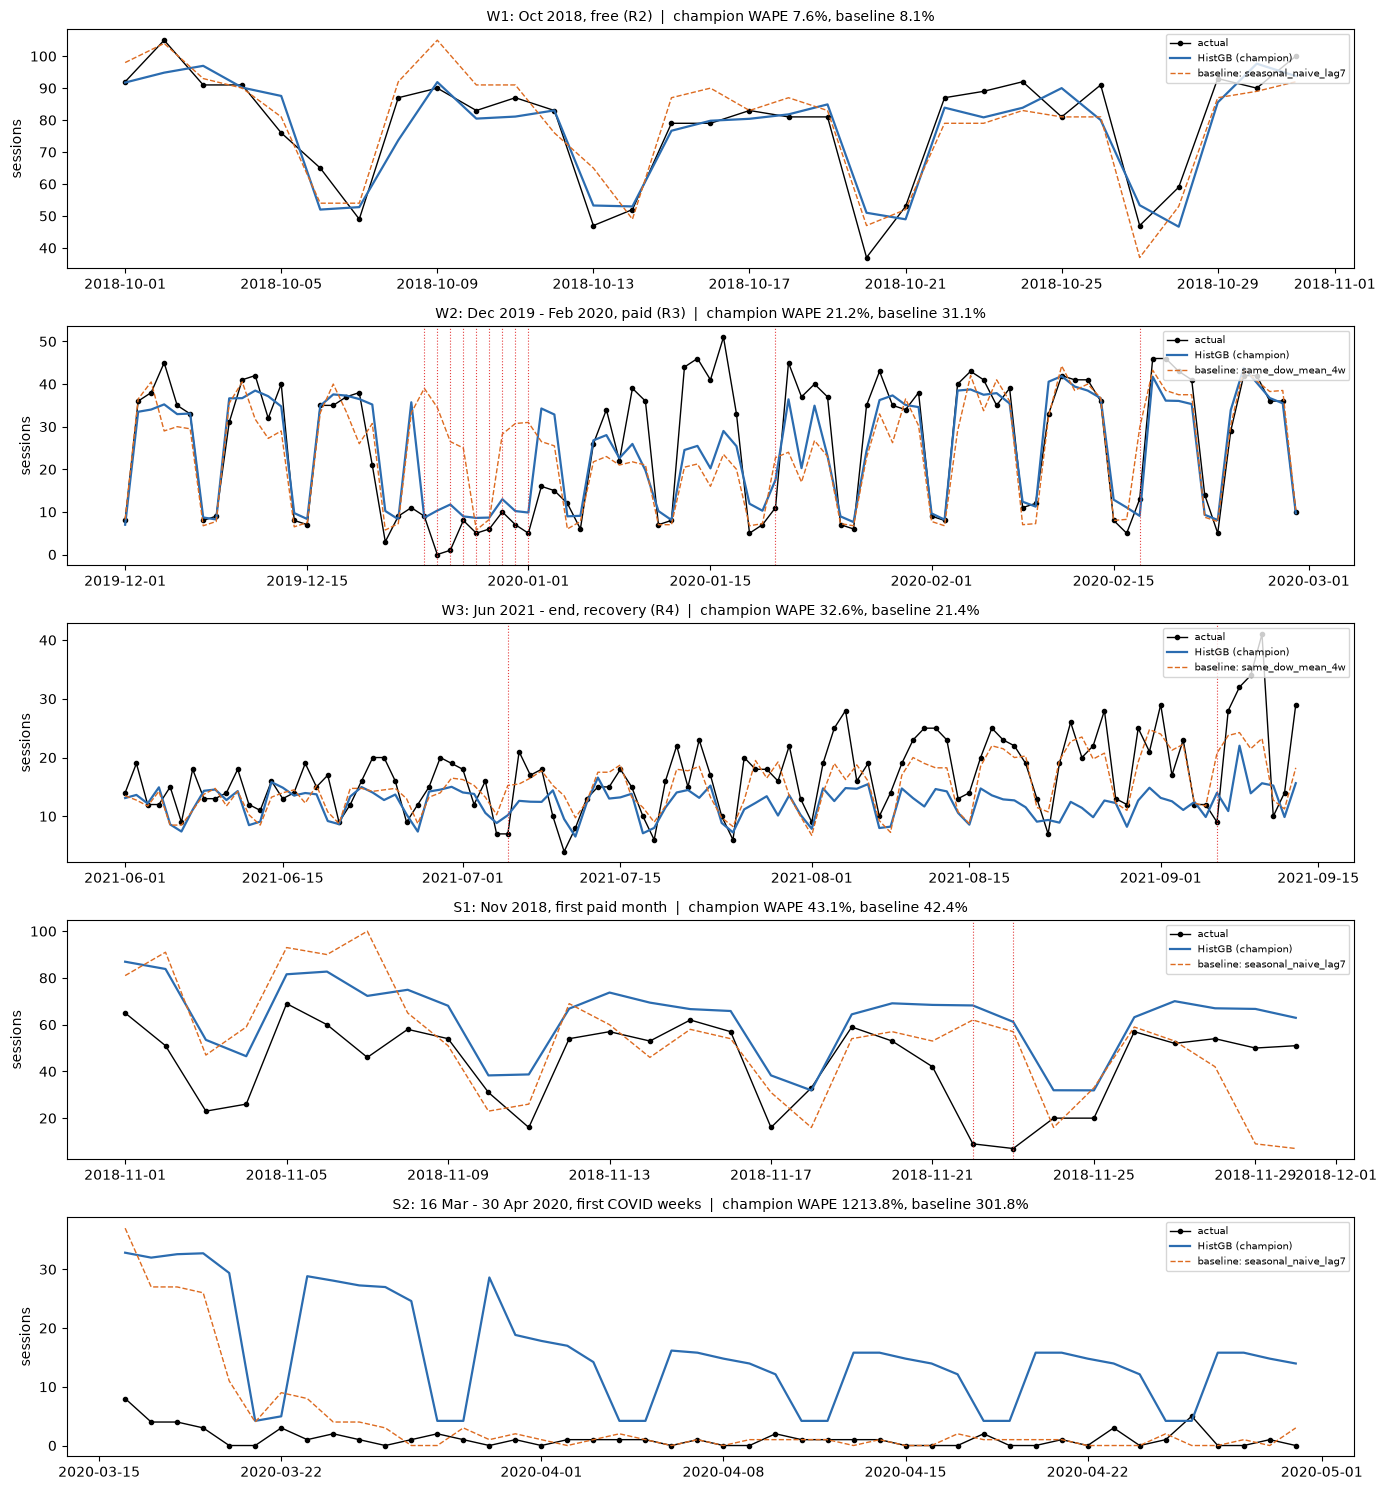

In [6]:
fig, axes = plt.subplots(len(WINDOWS), 1, figsize=(14, 3.0 * len(WINDOWS)))
for ax, w in zip(axes, WINDOWS):
    d = predictions[predictions.window == w]
    ax.plot(d["date"], d[TARGET], "k-o", ms=3, lw=1, label="actual")
    ax.plot(d["date"], d[f"pred_{CHAMPION}"], color="#2b6cb0", lw=1.6, label=f"{CHAMPION} (champion)")
    ax.plot(d["date"], d[f"pred_{best_adaptive[w]}"], color="#dd6b20", lw=1, ls="--", label=f"baseline: {best_adaptive[w]}")
    for _, r in d[d.is_major_holiday == 1].iterrows():
        ax.axvline(r["date"], color="#e53e3e", lw=0.8, ls=":")
    ax.set_title(f"{w}: {WINDOWS[w]['label']}  |  champion WAPE {vs_base.loc[w, 'champion_WAPE']:.1%}, "
                 f"baseline {vs_base.loc[w, 'baseline_WAPE']:.1%}", fontsize=10)
    ax.set_ylabel("sessions"); ax.legend(fontsize=7, loc="upper right")
plt.tight_layout(); plt.show()

## 4. Save champion

In [7]:
champion = {"model": CHAMPION, "selected_by": "lowest mean TimeSeriesSplit WAPE over main windows " + ", ".join(MAIN),
            "cv_WAPE_mean_main": float(cv_table.loc[CHAMPION, "mean_main"]),
            "params_per_window": {w: best_params[(w, CHAMPION)] for w in WINDOWS},
            "predictors_per_window": {w: WINDOWS[w]["predictors"] for w in WINDOWS},
            "model_files": {w: f"models/{w}_{CHAMPION}.joblib" for w in WINDOWS},
            "runner_up": cv_table.index[1], "cv_WAPE_runner_up": float(cv_table.iloc[1]["mean_main"])}
(ROOT / "champion.json").write_text(json.dumps(champion, indent=2))
print(json.dumps(champion, indent=2)[:1200])

{
  "model": "HistGB",
  "selected_by": "lowest mean TimeSeriesSplit WAPE over main windows W1, W2, W3",
  "cv_WAPE_mean_main": 0.3558065996517277,
  "params_per_window": {
    "W1": {
      "learning_rate": 0.05,
      "max_depth": null,
      "max_iter": 150,
      "min_samples_leaf": 10
    },
    "W2": {
      "learning_rate": 0.05,
      "max_depth": 3,
      "max_iter": 150,
      "min_samples_leaf": 10
    },
    "W3": {
      "learning_rate": 0.05,
      "max_depth": null,
      "max_iter": 300,
      "min_samples_leaf": 10
    },
    "S1": {
      "learning_rate": 0.05,
      "max_depth": 3,
      "max_iter": 150,
      "min_samples_leaf": 10
    },
    "S2": {
      "learning_rate": 0.05,
      "max_depth": 3,
      "max_iter": 150,
      "min_samples_leaf": 10
    }
  },
  "predictors_per_window": {
    "W1": [
      "dayofweek",
      "is_weekend",
      "dow_1",
      "dow_2",
      "dow_3",
      "dow_4",
      "dow_5",
      "dow_6",
      "is_major_holiday",
      "is_r

## 5. Summary (generated)

In [8]:
n_beat = int(vs_base.loc[MAIN, "beats_baseline"].sum())
lines = [f"- **{w}** ({WINDOWS[w]['label']}): {CHAMPION} WAPE {vs_base.loc[w, 'champion_WAPE']:.1%} (MAE {vs_base.loc[w, 'champion_MAE']:.1f}, "
         f"bias {vs_base.loc[w, 'champion_bias']:+.1f}) vs best adaptive baseline `{vs_base.loc[w, 'best_adaptive_baseline']}` "
         f"{vs_base.loc[w, 'baseline_WAPE']:.1%} → {vs_base.loc[w, 'WAPE_improvement_pts']:+.1f} points."
         for w in WINDOWS]
best_test = wape_tab[MAIN].mean(axis=1).idxmin()
text = f"""# Issue #14 summary (generated from the data)

- **Candidates:** {', '.join(CANDIDATES)}; tuned with 5-fold TimeSeriesSplit inside each window's training data.
- **Champion:** **{CHAMPION}** (mean CV WAPE {cv_table.loc[CHAMPION, 'mean_main']:.1%} over {', '.join(MAIN)}); runner-up {cv_table.index[1]} ({cv_table.iloc[1]['mean_main']:.1%}).
- **Test results (each scored once):**
""" + "\n".join(lines) + f"""
- The champion beats the best adaptive baseline in **{n_beat} of {len(MAIN)}** main windows.
- Lowest mean test WAPE over the main windows: **{best_test}**{' (same as the CV choice)' if best_test == CHAMPION else ' — differs from the CV choice; the CV choice is kept because test sets are not used for selection'}.
- Stress windows (S1, S2) are not used for selection; Issue #15 analyses them.
"""
(ROOT / "model_summary_i14.md").write_text(text, encoding="utf-8")
display(Markdown(text))

# Issue #14 summary (generated from the data)

- **Candidates:** Ridge, Lasso, ElasticNet, Poisson, RandomForest, GradientBoosting, HistGB; tuned with 5-fold TimeSeriesSplit inside each window's training data.
- **Champion:** **HistGB** (mean CV WAPE 35.6% over W1, W2, W3); runner-up RandomForest (37.9%).
- **Test results (each scored once):**
- **W1** (Oct 2018, free (R2)): HistGB WAPE 7.6% (MAE 5.9, bias -1.2) vs best adaptive baseline `seasonal_naive_lag7` 8.1% → +0.5 points.
- **W2** (Dec 2019 - Feb 2020, paid (R3)): HistGB WAPE 21.2% (MAE 5.4, bias -0.9) vs best adaptive baseline `same_dow_mean_4w` 31.1% → +9.9 points.
- **W3** (Jun 2021 - end, recovery (R4)): HistGB WAPE 32.6% (MAE 5.5, bias -4.6) vs best adaptive baseline `same_dow_mean_4w` 21.4% → -11.2 points.
- **S1** (Nov 2018, first paid month): HistGB WAPE 43.1% (MAE 18.8, bias +18.7) vs best adaptive baseline `seasonal_naive_lag7` 42.4% → -0.7 points.
- **S2** (16 Mar - 30 Apr 2020, first COVID weeks): HistGB WAPE 1213.8% (MAE 14.5, bias +14.5) vs best adaptive baseline `seasonal_naive_lag7` 301.8% → -912.0 points.
- The champion beats the best adaptive baseline in **2 of 3** main windows.
- Lowest mean test WAPE over the main windows: **ElasticNet** — differs from the CV choice; the CV choice is kept because test sets are not used for selection.
- Stress windows (S1, S2) are not used for selection; Issue #15 analyses them.
